# Exploratory data analysis (numpy + matplotlib only)

Structure: (1) load, (2) target, (3) missing values, (4) feature types & special codes,
(5) per-feature inspection, (6) link with the target, (7) redundancy, (8) train/test shift,
(9) summary of preprocessing decisions.
All statistics used for decisions are computed on the TRAIN set only (shift check excepted).

In [2]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
from helpers import load_csv_data

DATA_DIR = "dataset"   
SEED = 0
MISS_THRESHOLD = 80   # % missing above which a feature is a removal candidate (to tune by CV)
rng = np.random.default_rng(SEED)

## 1. Load the data

In [3]:
x_train, x_test, y_train, train_ids, test_ids = load_csv_data(DATA_DIR)

# Feature names come from the csv header (first column is the Id, dropped by load_csv_data)
with open(f"{DATA_DIR}/x_train.csv", "r") as f:
    feature_names = f.readline().strip().split(",")[1:]
name2idx = {name: i for i, name in enumerate(feature_names)}
print(feature_names)

assert len(feature_names) == x_train.shape[1] == x_test.shape[1]
print("x_train:", x_train.shape, "| x_test:", x_test.shape, "| y_train:", y_train.shape)

# The helper returns labels in {-1, 1}; logistic regression needs {0, 1}
print("Raw labels:", np.unique(y_train))
y01 = (y_train == 1).astype(float)

['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'IYEAR', 'DISPCODE', 'SEQNO', '_PSU', 'CTELENUM', 'PVTRESD1', 'COLGHOUS', 'STATERES', 'CELLFON3', 'LADULT', 'NUMADULT', 'NUMMEN', 'NUMWOMEN', 'CTELNUM1', 'CELLFON2', 'CADULT', 'PVTRESD2', 'CCLGHOUS', 'CSTATE', 'LANDLINE', 'HHADULT', 'GENHLTH', 'PHYSHLTH', 'MENTHLTH', 'POORHLTH', 'HLTHPLN1', 'PERSDOC2', 'MEDCOST', 'CHECKUP1', 'BPHIGH4', 'BPMEDS', 'BLOODCHO', 'CHOLCHK', 'TOLDHI2', 'CVDSTRK3', 'ASTHMA3', 'ASTHNOW', 'CHCSCNCR', 'CHCOCNCR', 'CHCCOPD1', 'HAVARTH3', 'ADDEPEV2', 'CHCKIDNY', 'DIABETE3', 'DIABAGE2', 'SEX', 'MARITAL', 'EDUCA', 'RENTHOM1', 'NUMHHOL2', 'NUMPHON2', 'CPDEMO1', 'VETERAN3', 'EMPLOY1', 'CHILDREN', 'INCOME2', 'INTERNET', 'WEIGHT2', 'HEIGHT3', 'PREGNANT', 'QLACTLM2', 'USEEQUIP', 'BLIND', 'DECIDE', 'DIFFWALK', 'DIFFDRES', 'DIFFALON', 'SMOKE100', 'SMOKDAY2', 'STOPSMK2', 'LASTSMK2', 'USENOW3', 'ALCDAY5', 'AVEDRNK2', 'DRNK3GE5', 'MAXDRNKS', 'FRUITJU1', 'FRUIT1', 'FVBEANS', 'FVGREEN', 'FVORANG', 'VEGETAB1', 'EXERANY2', 'EXRACT11'

## 2. Target

Positive rate (MICHD): 8.83%
Accuracy of 'always predict 0': 91.17%  -> accuracy is a misleading metric here


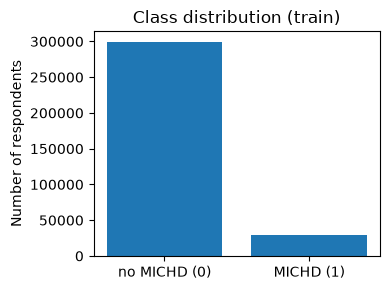

In [4]:
p = y01.mean()
print(f"Positive rate (MICHD): {p*100:.2f}%")
print(f"Accuracy of 'always predict 0': {(1-p)*100:.2f}%  -> accuracy is a misleading metric here")

plt.figure(figsize=(4, 3))
plt.bar(["no MICHD (0)", "MICHD (1)"], [np.sum(y01 == 0), np.sum(y01 == 1)])
plt.ylabel("Number of respondents")
plt.title("Class distribution (train)")
plt.tight_layout()
plt.show()

## 3. Missing values

Features with >  0% missing: 239
Features with > 10% missing: 182
Features with > 50% missing: 147
Features with > 80% missing: 116


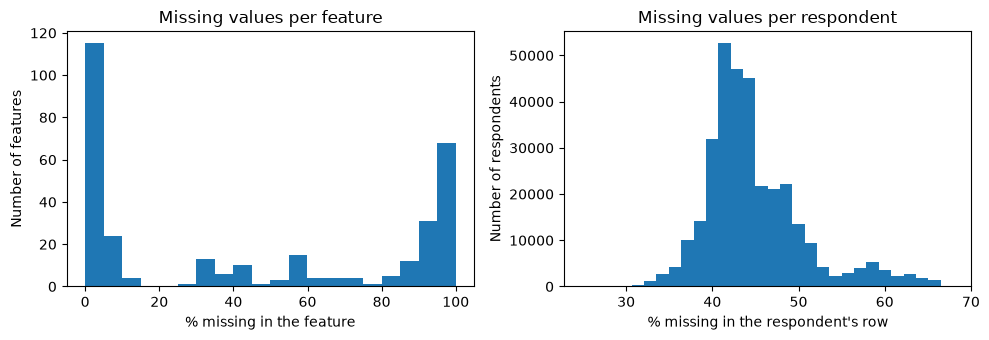


20 features with the most missing values:
   14 LADULT              99.99%
   11 COLGHOUS            99.99%
  191 PCDMDECN            99.95%
  147 ASERVIST            99.93%
  148 ASDRVIST            99.93%
  152 ASNOSLEP            99.90%
  154 ASINHALR            99.85%
  153 ASTHMED3            99.85%
  151 ASYMPTOM            99.85%
  150 ASACTLIM            99.85%
  149 ASRCHKUP            99.85%
  146 ASATTACK            99.85%
  156 STREHAB1            99.84%
  190 PCPSADE1            99.82%
  155 HAREHAB1            99.76%
  145 ASTHMAGE            99.76%
  130 VINOCRE2            99.76%
   22 CCLGHOUS            99.76%
  168 HPVADSHT            99.67%
  131 VIEYEXM2            99.43%


In [5]:
miss_pct = np.isnan(x_train).mean(axis=0) * 100

for thr in (0, 10, 50, 80):
    print(f"Features with > {thr:>2}% missing: {np.sum(miss_pct > thr)}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(miss_pct, bins=20)
ax[0].set_xlabel("% missing in the feature")
ax[0].set_ylabel("Number of features")
ax[0].set_title("Missing values per feature")

row_miss = np.isnan(x_train).mean(axis=1) * 100
ax[1].hist(row_miss, bins=30)
ax[1].set_xlabel("% missing in the respondent's row")
ax[1].set_ylabel("Number of respondents")
ax[1].set_title("Missing values per respondent")
plt.tight_layout()
plt.show()

print("\n20 features with the most missing values:")
for j in np.argsort(miss_pct)[::-1][:20]:
    print(f"  {j:>3} {feature_names[j]:<18} {miss_pct[j]:6.2f}%")

## 4. Special codes (recoding) and feature types
BRFSS encodes "don't know / refused / none" with numeric codes (7, 9, 77, 99, 88, ...)
that are NOT real values. `special_codes.py` recodes them (rules extracted from the official
BRFSS 2015 codebook) and converts WEIGHT2 / HEIGHT3 to kg / cm.

In [6]:
from special_codes import recode, convert_units

x_rec = convert_units(recode(x_train, name2idx), name2idx)
miss_pct = np.isnan(x_rec).mean(axis=0) * 100   # recomputed: recoding adds NaNs

# Safety check: these columns define the target and must NOT be among the features
print("Target-defining columns present:", [c for c in ("CVDINFR4", "CVDCRHD4", "_MICHD") if c in name2idx])

Target-defining columns present: []


In [7]:
# Feature types, computed AFTER recoding (otherwise a yes/no feature with codes 7, 9 looks like 4 values)
n_unique = np.array([np.unique(c[~np.isnan(c)]).size for c in x_rec.T])
kind = np.where(n_unique <= 1, "constant",
        np.where(n_unique == 2, "binary",
         np.where(n_unique <= 15, "categorical", "many-valued")))
for k in ("constant", "binary", "categorical", "many-valued"):
    print(f"{k:<12}: {np.sum(kind == k)} features")
print("Constant features:", [feature_names[j] for j in np.where(kind == "constant")[0]])

constant    : 6 features
binary      : 100 features
categorical : 133 features
many-valued : 82 features
Constant features: ['CTELENUM', 'COLGHOUS', 'STATERES', 'CTELNUM1', 'CELLFON2', 'CCLGHOUS']


## 5. Per-feature inspection (with link to the target)

In [8]:
def describe_feature(j, x=None, y=y01, top=8):
    """Missing rate, most frequent values, and P(y=1) for each of them."""
    x = x_rec if x is None else x
    col = x[:, j]
    m = np.isnan(col)
    vals, cnts = np.unique(col[~m], return_counts=True)
    print("=" * 55)
    print(f"[{j}] {feature_names[j]} | missing {m.mean()*100:.2f}% | {len(vals)} unique values")
    print(f"  {'value':>8} {'count':>8} {'% rows':>7} {'P(y=1)':>7}")
    for k in np.argsort(cnts)[::-1][:top]:
        sel = col == vals[k]
        print(f"  {vals[k]:>8g} {cnts[k]:>8d} {cnts[k]/len(col)*100:>6.1f}% {y[sel].mean():>7.3f}")
    if m.any():
        print(f"  {'NaN':>8} {m.sum():>8d} {m.mean()*100:>6.1f}% {y[m].mean():>7.3f}")

for name in ("GENHLTH", "PHYSHLTH", "MENTHLTH"):
    describe_feature(name2idx[name])

[26] GENHLTH | missing 0.27% | 5 unique values
     value    count  % rows  P(y=1)
         2   108089   32.9%   0.042
         3   101880   31.0%   0.091
         1    56937   17.4%   0.021
         4    43349   13.2%   0.193
         5    16992    5.2%   0.319
       NaN      888    0.3%   0.160
[27] PHYSHLTH | missing 2.17% | 31 unique values
     value    count  % rows  P(y=1)
         0   204264   62.2%   0.059
        30    25233    7.7%   0.229
         2    18182    5.5%   0.072
         1    13676    4.2%   0.050
         3    10553    3.2%   0.091
         5     9207    2.8%   0.110
        10     6754    2.1%   0.153
        15     6150    1.9%   0.187
       NaN     7108    2.2%   0.162
[28] MENTHLTH | missing 1.63% | 31 unique values
     value    count  % rows  P(y=1)
         0   224183   68.3%   0.084
        30    16379    5.0%   0.156
         2    15809    4.8%   0.066
         5    10985    3.3%   0.080
         1    10190    3.1%   0.053
         3     9108    2.8%

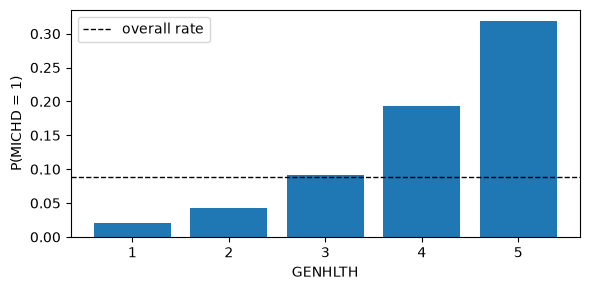

In [9]:
def plot_rate_by_value(j, x=None, y=y01, max_values=15):
    """Bar plot of P(y=1) per value of a categorical/ordinal feature."""
    x = x_rec if x is None else x
    col = x[:, j]
    vals = np.unique(col[~np.isnan(col)])[:max_values]
    rates = [y[col == v].mean() for v in vals]
    plt.figure(figsize=(6, 3))
    plt.bar([f"{v:g}" for v in vals], rates)
    plt.axhline(y.mean(), color="k", ls="--", lw=1, label="overall rate")
    plt.xlabel(feature_names[j]); plt.ylabel("P(MICHD = 1)")
    plt.legend(); plt.tight_layout(); plt.show()

plot_rate_by_value(name2idx["GENHLTH"])

## 6. Link with the target (all features)

Top 20 features by |corr| with the target (crude for categorical codes, use as a guide):
  157 CVDASPRN           corr=-0.257  miss-indicator corr=-0.004
   26 GENHLTH            corr=+0.249  miss-indicator corr=+0.013
  230 _RFHLTH            corr=+0.235  miss-indicator corr=+0.013
  246 _AGEG5YR           corr=+0.227  miss-indicator corr=-0.012
  248 _AGE80             corr=+0.225  miss-indicator corr=+nan
  232 _RFHYPE5           corr=+0.218  miss-indicator corr=+0.005
   69 DIFFWALK           corr=-0.216  miss-indicator corr=-0.003
   58 EMPLOY1            corr=+0.212  miss-indicator corr=-0.006
  144 DRADVISE           corr=-0.211  miss-indicator corr=-0.023
  249 _AGE_G             corr=+0.207  miss-indicator corr=+nan
   39 CVDSTRK3           corr=-0.207  miss-indicator corr=+0.038
   34 BPHIGH4            corr=-0.205  miss-indicator corr=-0.001
  247 _AGE65YR           corr=+0.204  miss-indicator corr=-0.012
   66 USEEQUIP           corr=-0.193  miss-indicator corr=-0.007
   65

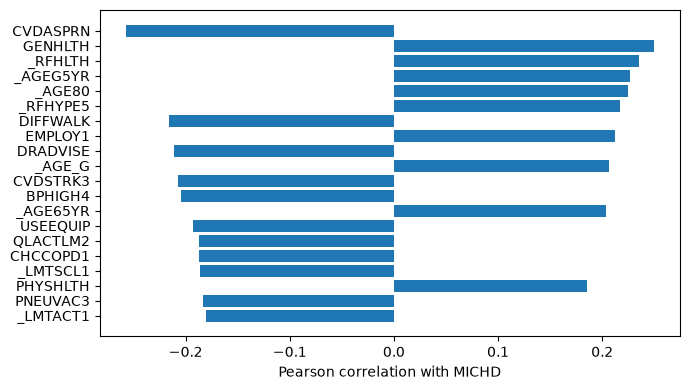

In [10]:
def corr_with_target(x, y, min_n=1000):
    """Pearson corr with y on non-missing rows; NaN if < min_n observed rows or ~constant."""
    out = np.full(x.shape[1], np.nan)
    n_obs = (~np.isnan(x)).sum(axis=0)
    for j in range(x.shape[1]):
        m = ~np.isnan(x[:, j])
        if n_obs[j] >= min_n and x[m, j].std() > 1e-9:
            out[j] = np.corrcoef(x[m, j], y[m])[0, 1]
    return out, n_obs

corr_y, n_obs = corr_with_target(x_rec, y01)
# Is the *fact of being missing* informative?
corr_miss_y, _ = corr_with_target(np.isnan(x_rec).astype(float), y01)

top = np.argsort(-np.nan_to_num(np.abs(corr_y)))[:20]
print("Top 20 features by |corr| with the target (crude for categorical codes, use as a guide):")
for j in top:
    print(f"  {j:>3} {feature_names[j]:<18} corr={corr_y[j]:+.3f}  miss-indicator corr={corr_miss_y[j]:+.3f}")

plt.figure(figsize=(7, 4))
plt.barh([feature_names[j] for j in top][::-1], corr_y[top][::-1])
plt.xlabel("Pearson correlation with MICHD"); plt.tight_layout(); plt.show()
# CAUTION: a suspiciously high correlation can mean the feature is (almost) a definition of the target.

## 7. Redundancy between features

In [11]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    mu = np.nanmean(x_rec, axis=0)
    sd = np.nanstd(x_rec, axis=0)

usable = np.where((miss_pct < 50) & (sd > 0))[0]
sub = rng.choice(len(x_rec), size=min(50_000, len(x_rec)), replace=False)  # subsample: keeps it fast
z = np.nan_to_num((x_rec[sub][:, usable] - mu[usable]) / sd[usable])  # mean-imputation (0 after z-score)
corr = np.corrcoef(z, rowvar=False)

iu = np.triu_indices(len(usable), k=1)
pairs = np.where(np.abs(corr[iu]) > 0.95)[0]
print(f"{len(pairs)} pairs with |corr| > 0.95 (among {len(usable)} usable features):")
for p_ in pairs[:30]:
    a, b = usable[iu[0][p_]], usable[iu[1][p_]]
    print(f"  {feature_names[a]:<16} ~ {feature_names[b]:<16} r={corr[iu][p_]:+.3f}")


# For each redundant pair, drop the feature least correlated with the target
drop_redundant = set()
for p_ in pairs:
    a, b = usable[iu[0][p_]], usable[iu[1][p_]]
    if a in drop_redundant or b in drop_redundant:
        continue
    drop_redundant.add(a if abs(np.nan_to_num(corr_y[a])) < abs(np.nan_to_num(corr_y[b])) else b)
print(len(drop_redundant), "redundant features to drop:", [feature_names[j] for j in sorted(drop_redundant)])

27 pairs with |corr| > 0.95 (among 171 usable features):
  _STATE           ~ _STSTR           r=+1.000
  IDATE            ~ IMONTH           r=+1.000
  SEQNO            ~ _PSU             r=+1.000
  BPHIGH4          ~ _RFHYPE5         r=-0.951
  TOLDHI2          ~ _RFCHOL          r=-1.000
  HAVARTH3         ~ _DRDXAR1         r=+1.000
  EDUCA            ~ _EDUCAG          r=+0.988
  INCOME2          ~ _INCOMG          r=+0.977
  WEIGHT2          ~ WTKG3            r=+1.000
  HEIGHT3          ~ HTIN4            r=+0.994
  HEIGHT3          ~ HTM4             r=+1.000
  ALCDAY5          ~ DRNKANY5         r=+0.989
  EXERANY2         ~ _TOTINDA         r=+1.000
  EXERHMM1         ~ PADUR1_          r=+0.996
  _STRWT           ~ _WT2RAKE         r=+0.954
  _RACE            ~ _RACEGR3         r=+0.989
  _AGEG5YR         ~ _AGE80           r=+0.995
  _AGEG5YR         ~ _AGE_G           r=+0.968
  _AGE80           ~ _AGE_G           r=+0.971
  HTIN4            ~ HTM4             r=+0.994
  _

## 8. Train / test shift

In [12]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    x_test_rec = convert_units(recode(x_test, name2idx), name2idx)
    std_diff = (np.nanmean(x_test_rec, axis=0) - mu) / np.where(sd > 0, sd, np.nan)
# Ignore features observed on < 1000 rows (train or test): their shift is just noise
ok = ((~np.isnan(x_rec)).sum(0) >= 1000) & ((~np.isnan(x_test_rec)).sum(0) >= 1000)
std_diff[~ok] = np.nan
miss_diff = (np.isnan(x_test).mean(axis=0) - np.isnan(x_train).mean(axis=0)) * 100

print("Features with largest standardized mean shift train -> test:")
for j in np.argsort(-np.nan_to_num(np.abs(std_diff)))[:10]:
    print(f"  {feature_names[j]:<18} shift={std_diff[j]:+.3f} std | missing diff={miss_diff[j]:+.2f} pts")
# Test and train come from the same survey: anything large here deserves a closer look.

Features with largest standardized mean shift train -> test:
  LENGEXAM           shift=+0.081 std | missing diff=+0.04 pts
  PROFEXAM           shift=+0.074 std | missing diff=+0.02 pts
  CRGVMST2           shift=-0.044 std | missing diff=-0.03 pts
  PCPSAAD2           shift=-0.037 std | missing diff=-0.06 pts
  ASPUNSAF           shift=-0.037 std | missing diff=+0.04 pts
  FEETCHK2           shift=+0.031 std | missing diff=-0.06 pts
  CDHELP             shift=-0.030 std | missing diff=-0.05 pts
  TETANUS            shift=+0.029 std | missing diff=-0.07 pts
  CDASSIST           shift=-0.029 std | missing diff=-0.05 pts
  CDSOCIAL           shift=-0.029 std | missing diff=-0.04 pts


## 9. Preprocessing decisions (computed, not just written in markdown)

In [13]:
drop_constant = set(np.where(sd == 0)[0]) | set(np.where(np.isnan(sd))[0])
drop_missing = set(np.where(miss_pct > MISS_THRESHOLD)[0])
print(f"Constant/empty: {len(drop_constant)} | > {MISS_THRESHOLD}% missing: {len(drop_missing)} | redundant: {len(drop_redundant)}")
drop_all = drop_constant | drop_missing | drop_redundant
print(f"Candidates for removal: {len(drop_all)} / {x_train.shape[1]}")
# Next step: move auto_rules/recode_special_codes + these choices into a preprocessing function
# (not in the notebook) so that run.py applies exactly the same pipeline to the test set.

Constant/empty: 6 | > 80% missing: 117 | redundant: 23
Candidates for removal: 144 / 321


## 10. Report figures (seaborn, not saved yet)
Sizes are chosen for a two-column LaTeX page: ~3.4 in = one column, ~7.2 in = full width.
Run this section last (it reuses `corr_y`, `drop_redundant`, `sub`, `MISS_THRESHOLD`, ...).

In [14]:
import seaborn as sns

sns.set_theme(style="whitegrid", context="paper", font_scale=0.9)
PAL = sns.color_palette("colorblind")
C_NEG, C_POS = PAL[0], PAL[1]     # same colors for "no MICHD" / "MICHD" in every figure
SAVE_FIGS = False                  # set to True when the figures are final
FIG_DIR = "figures"

def finish(fig, name):
    fig.tight_layout()
    if SAVE_FIGS:
        import os
        os.makedirs(FIG_DIR, exist_ok=True)
        fig.savefig(f"{FIG_DIR}/{name}.pdf", bbox_inches="tight")   # vector PDF for LaTeX
    plt.show()

def rate_ci(mask, y):
    """P(y=1) and 95% half-width (normal approximation) for the rows selected by mask."""
    r = y[mask].mean()
    return r, 1.96 * np.sqrt(r * (1 - r) / mask.sum())

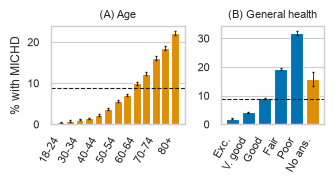

In [22]:
AGE_LABELS = ["18-24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54",
              "55-59", "60-64", "65-69", "70-74", "75-79", "80+"]       # _AGEG5YR codes 1..13
GH_LABELS = ["Exc.", "V. good", "Good", "Fair", "Poor", "No ans."]

SAVE_FIGS =True

age = x_rec[:, name2idx["_AGEG5YR"]]
gh = x_rec[:, name2idx["GENHLTH"]]
 
fig, ax = plt.subplots(1, 2, figsize=(3.4, 1.9), gridspec_kw={"width_ratios": [1.3, 1]})
 

st = np.array([rate_ci(age == c, y01) for c in range(1, 14)]) * 100
ax[0].bar(np.arange(13), st[:, 0], color=C_POS)
ax[0].errorbar(np.arange(13), st[:, 0], yerr=st[:, 1], fmt="none", ecolor="k", capsize=1, lw=0.6)
ax[0].axhline(p * 100, color="k", ls="--", lw=0.8)
ax[0].set_xticks(np.arange(0, 13, 2))                       # une etiquette sur deux, pour la lisibilite
ax[0].set_xticklabels(AGE_LABELS[::2], rotation=60, ha="right")
ax[0].grid(axis="x", visible=False)
ax[0].set_title("(A) Age", fontsize=8)
ax[0].set_ylabel("% with MICHD")
 
# (B) taux de MICHD par sante generale ("No ans." = NaN apres recodage)
masks = [gh == c for c in (1, 2, 3, 4, 5)] + [np.isnan(gh)]
st = np.array([rate_ci(m, y01) for m in masks]) * 100
ax[1].bar(np.arange(6), st[:, 0], color=[C_NEG] * 5 + [C_POS])
ax[1].errorbar(np.arange(6), st[:, 0], yerr=st[:, 1], fmt="none", ecolor="k", capsize=1, lw=0.6)
ax[1].axhline(p * 100, color="k", ls="--", lw=0.8)
ax[1].set_xticks(np.arange(6))
ax[1].set_xticklabels(GH_LABELS, rotation=60, ha="right")
ax[1].grid(axis="x", visible=False)
ax[1].set_title("(B) General health", fontsize=8)
 
finish(fig, "fig1_compact")   

### Figure 1 - Overview: missing values, class balance, age effect

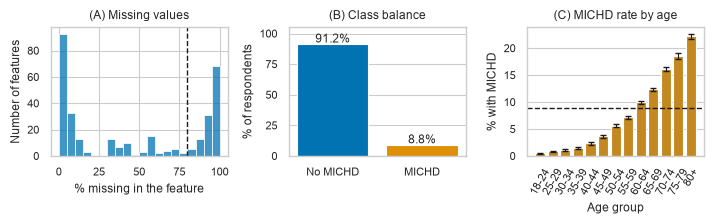

In [16]:
AGE_LABELS = ["18-24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54",
              "55-59", "60-64", "65-69", "70-74", "75-79", "80+"]       # _AGEG5YR codes 1..13
age = x_rec[:, name2idx["_AGEG5YR"]]

fig, ax = plt.subplots(1, 3, figsize=(7.2, 2.3))

# (A) missing values per feature
sns.histplot(miss_pct, bins=20, color=C_NEG, ax=ax[0])
ax[0].axvline(MISS_THRESHOLD, color="k", ls="--", lw=1)
ax[0].set(xlabel="% missing in the feature", ylabel="Number of features", title="(A) Missing values")

# (B) class balance
shares = [(1 - p) * 100, p * 100]
ax[1].bar(["No MICHD", "MICHD"], shares, color=[C_NEG, C_POS])
for k, v in enumerate(shares):
    ax[1].text(k, v + 1.5, f"{v:.1f}%", ha="center")
ax[1].set(ylabel="% of respondents", ylim=(0, 105), title="(B) Class balance")
ax[1].grid(axis="x", visible=False)

# (C) MICHD rate by age group, with 95% confidence intervals
stats = np.array([rate_ci(age == c, y01) for c in range(1, 14)]) * 100
sns.barplot(x=AGE_LABELS, y=stats[:, 0], color=C_POS, ax=ax[2])
ax[2].errorbar(np.arange(13), stats[:, 0], yerr=stats[:, 1], fmt="none", ecolor="k", capsize=2, lw=0.8)
ax[2].axhline(p * 100, color="k", ls="--", lw=1)
ax[2].tick_params(axis="x", rotation=60)
ax[2].set(xlabel="Age group", ylabel="% with MICHD", title="(C) MICHD rate by age")
finish(fig, "fig1_overview")

### Figure 2 - Most informative features (one per group of redundant features)

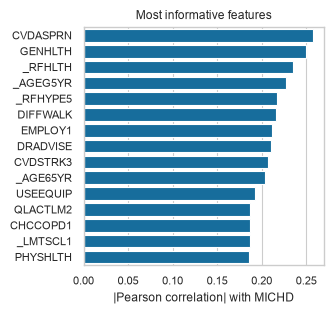

In [17]:
order = np.argsort(-np.nan_to_num(np.abs(corr_y)))
top = [j for j in order if j not in drop_redundant][:15]

fig, ax = plt.subplots(figsize=(3.4, 3.2))
sns.barplot(x=np.abs(corr_y[top]), y=[feature_names[j] for j in top], orient="h", color=C_NEG, ax=ax)
ax.set(xlabel="|Pearson correlation| with MICHD", ylabel="", title="Most informative features")
finish(fig, "fig2_top_features")
# Sign omitted on purpose: for yes/no features it only reflects how the answers are coded (1=yes, 2=no).

### Figure 3 - Non-linear effect of general health, and missingness is informative

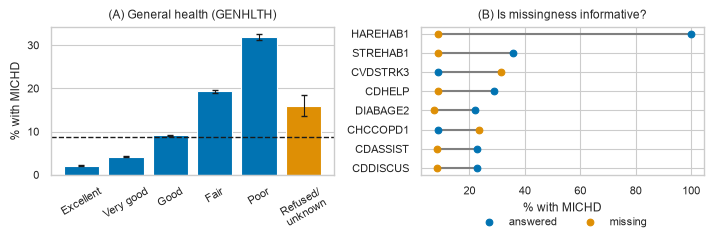

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.6))

# (A) MICHD rate by self-reported general health (non-linear, convex)
g = x_rec[:, name2idx["GENHLTH"]]
labels = ["Excellent", "Very good", "Good", "Fair", "Poor", "Refused/\nunknown"]
masks = [g == c for c in (1, 2, 3, 4, 5)] + [np.isnan(g)]
st = np.array([rate_ci(m, y01) for m in masks]) * 100
ax[0].bar(labels, st[:, 0], color=[C_NEG] * 5 + [C_POS])
ax[0].errorbar(np.arange(6), st[:, 0], yerr=st[:, 1], fmt="none", ecolor="k", capsize=2, lw=0.8)
ax[0].axhline(p * 100, color="k", ls="--", lw=1)
ax[0].tick_params(axis="x", rotation=30)
ax[0].grid(axis="x", visible=False)
ax[0].set(ylabel="% with MICHD", title="(A) General health (GENHLTH)")

# (B) MICHD rate when the answer is missing vs. given, features with the largest gap
isn = np.isnan(x_rec)
n_nan, n_ok = isn.sum(0), (~isn).sum(0)
cand = np.where((n_nan >= 500) & (n_ok >= 500))[0]
r_nan = np.array([y01[isn[:, j]].mean() for j in cand]) * 100
r_ok = np.array([y01[~isn[:, j]].mean() for j in cand]) * 100
sel = np.argsort(-np.abs(r_nan - r_ok))[:8]
ypos = np.arange(len(sel))
ax[1].hlines(ypos, r_ok[sel], r_nan[sel], color="gray", lw=1.5)
ax[1].scatter(r_ok[sel], ypos, color=C_NEG, label="answered", zorder=3)
ax[1].scatter(r_nan[sel], ypos, color=C_POS, label="missing", zorder=3)
ax[1].set_yticks(ypos)
ax[1].set_yticklabels([feature_names[cand[j]] for j in sel])
ax[1].invert_yaxis()
ax[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, frameon=False)   # below the plot
ax[1].set(xlabel="% with MICHD", title="(B) Is missingness informative?")
finish(fig, "fig3_health_and_missingness")

### Figure 4 - Correlations among the 20 features most linked to the target

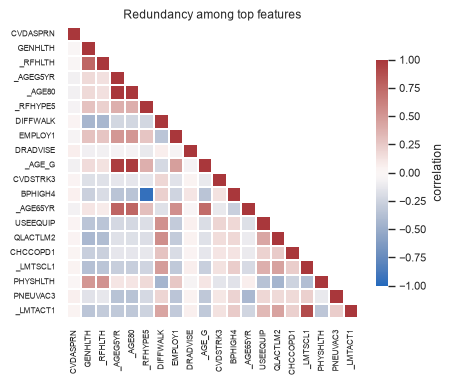

In [19]:
top20 = np.argsort(-np.nan_to_num(np.abs(corr_y)))[:20]
X = x_rec[sub][:, top20]
X = np.where(np.isnan(X), np.nanmean(X, axis=0), X)      # mean imputation, only for this plot
C = np.corrcoef(X, rowvar=False)
names20 = [feature_names[j] for j in top20]

fig, ax = plt.subplots(figsize=(4.6, 4))
sns.heatmap(C, mask=np.triu(np.ones_like(C, dtype=bool), k=1), cmap="vlag", vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.3, xticklabels=names20, yticklabels=names20,
            cbar_kws={"shrink": 0.7, "label": "correlation"}, ax=ax)
ax.grid(False)
ax.tick_params(labelsize=6)
ax.set_title("Redundancy among top features")
finish(fig, "fig4_correlation_heatmap")